# Waste Management India – Daily Waste Generation (tons/day) Prediction
**Problem type:** Supervised **Regression** (target `Daily_Waste_Generation_Tons` is continuous).
Steps: 1 Load → 2 Clean → 3 EDA → 4 Train/Test → 5 Models → 6 Evaluate (+confusion matrix) → 7 Tune (+confusion matrix).
No `Pipeline`, no `SimpleImputer` – encoding / scaling done manually.

In [15]:
import os, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt, seaborn as sns, warnings
from scipy.stats import shapiro
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, confusion_matrix, accuracy_score, ConfusionMatrixDisplay
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
OUT = "out/"
os.makedirs(OUT, exist_ok=True)   # folder for saved plots/results
def save(name):
    plt.tight_layout(); plt.savefig(OUT + name, dpi=110); plt.show(); plt.close()

## Step 1 – Data loading

In [16]:
data = pd.read_csv(r"C:\Users\Kshitij\Downloads\Waste_Management_India.csv")
print(data.shape); print(data.head())

(25203, 11)
        City          State     Region City_Category  Year  Month  Season  \
0   Agartala        Tripura  Northeast        Tier-3  2015      1  Winter   
1       Agra  Uttar Pradesh    Central        Tier-1  2015      1  Winter   
2       Agra  Uttar Pradesh    Central        Tier-1  2015      1  Winter   
3  Ahmedabad        Gujarat       West         Metro  2015      1  Winter   
4  Ahmedabad        Gujarat       West         Metro  2015      1  Winter   

   Population    Waste_Type  Daily_Waste_Generation_Tons  \
0      172974       E-Waste                         0.91   
1     1632551       Organic                       273.06   
2     1632551       Plastic                        90.35   
3     7453456  Construction                       614.79   
4     7453456       Organic                      1674.59   

   Garbage_Collection_Frequency  
0                             1  
1                             5  
2                             5  
3                           

## Step 2 – Cleaning

In [17]:
data.info()
print("Nulls:\n", data.isnull().sum())
print("Duplicates:", data.duplicated().sum())
print(data.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25203 entries, 0 to 25202
Data columns (total 11 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   City                          25203 non-null  object 
 1   State                         25203 non-null  object 
 2   Region                        25203 non-null  object 
 3   City_Category                 25203 non-null  object 
 4   Year                          25203 non-null  int64  
 5   Month                         25203 non-null  int64  
 6   Season                        25203 non-null  object 
 7   Population                    25203 non-null  int64  
 8   Waste_Type                    25203 non-null  object 
 9   Daily_Waste_Generation_Tons   25203 non-null  float64
 10  Garbage_Collection_Frequency  25203 non-null  int64  
dtypes: float64(1), int64(4), object(6)
memory usage: 2.1+ MB
Nulls:
 City                            0
State               

**Domain-driven column decisions**
- `City` (130 values): dropped as a model input – its effect is carried by `Population`, `City_Category`, `State`. (Kept in a lookup table for city-level prediction later.)
- `Region`: dropped – fully determined by `State` (redundant).
- `Season`: dropped – fully determined by `Month` (redundant).
- Kept: `State`, `City_Category`, `Year`, `Month`, `Population`, `Waste_Type`, `Garbage_Collection_Frequency`.

No nulls/duplicates here, but a manual median/mode fill is included so the code is robust (instead of SimpleImputer).

In [18]:
lookup = data[["City", "State", "Region", "City_Category"]].drop_duplicates("City").set_index("City")
for c in data.columns:
    if data[c].isnull().any():
        data[c] = data[c].fillna(data[c].median() if data[c].dtype != object else data[c].mode()[0])
data = data.drop_duplicates()
df = data.drop(columns=["City", "Region", "Season"]).copy()
print(df.columns.tolist())

['State', 'City_Category', 'Year', 'Month', 'Population', 'Waste_Type', 'Daily_Waste_Generation_Tons', 'Garbage_Collection_Frequency']


## Step 3 – EDA

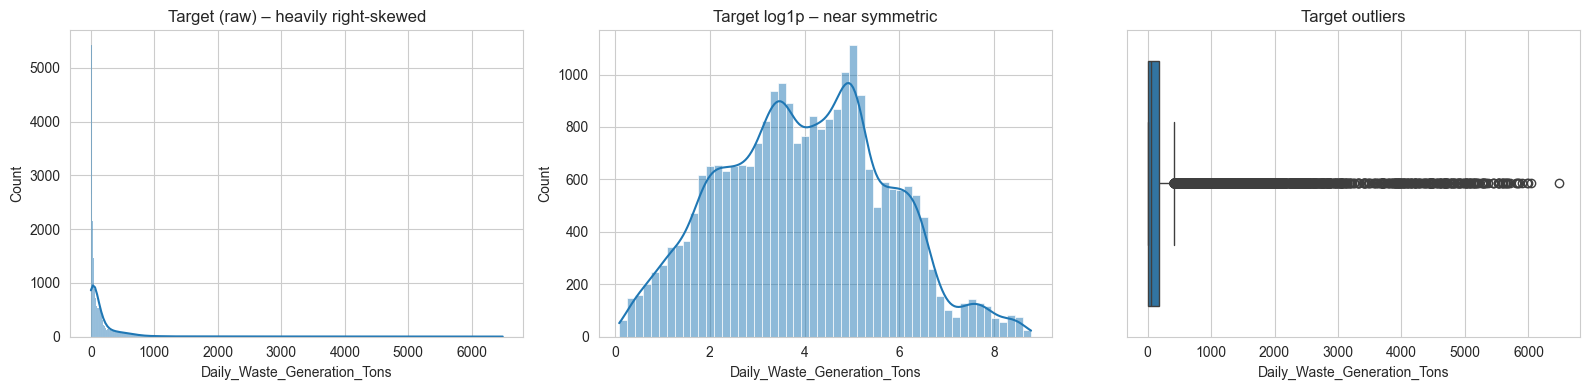

skew raw: 5.64  skew log1p: 0.08
Shapiro p (raw): 4.747402509211926e-85


In [19]:
target = "Daily_Waste_Generation_Tons"
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df[target], kde=True, ax=ax[0]); ax[0].set_title("Target (raw) – heavily right-skewed")
sns.histplot(np.log1p(df[target]), kde=True, ax=ax[1]); ax[1].set_title("Target log1p – near symmetric")
sns.boxplot(x=df[target], ax=ax[2]); ax[2].set_title("Target outliers")
save("eda_target.png")
print("skew raw:", df[target].skew().round(2), " skew log1p:", np.log1p(df[target]).skew().round(2))
stat, p = shapiro(df[target].sample(5000, random_state=42)); print("Shapiro p (raw):", p)

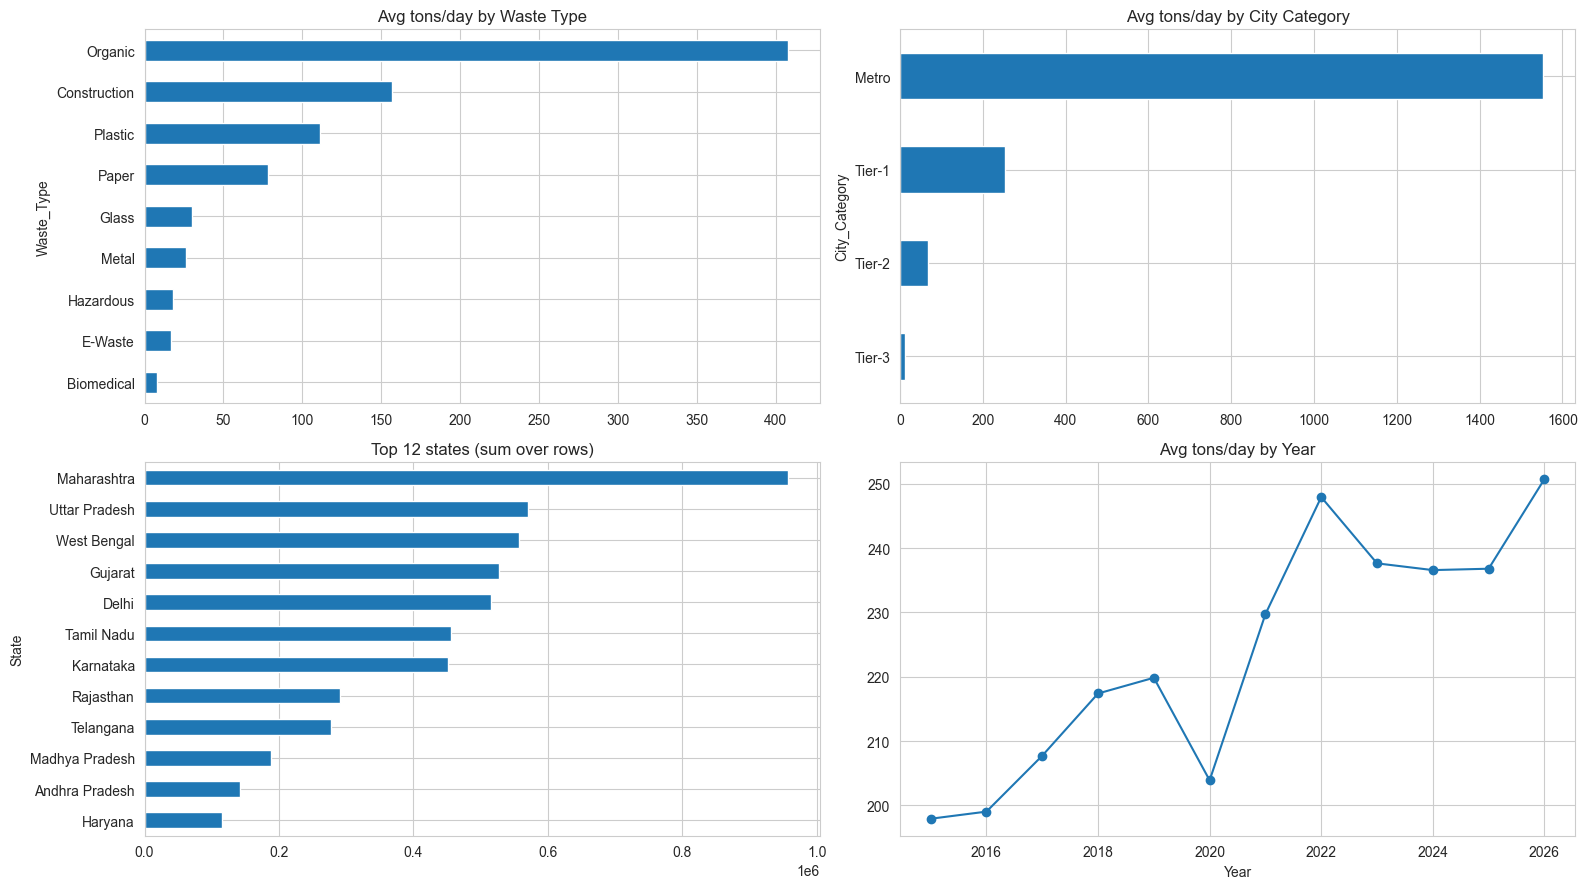

In [20]:
fig, ax = plt.subplots(2, 2, figsize=(16, 9))
df.groupby("Waste_Type")[target].mean().sort_values().plot.barh(ax=ax[0, 0], title="Avg tons/day by Waste Type")
df.groupby("City_Category")[target].mean().sort_values().plot.barh(ax=ax[0, 1], title="Avg tons/day by City Category")
df.groupby("State")[target].sum().sort_values().tail(12).plot.barh(ax=ax[1, 0], title="Top 12 states (sum over rows)")
df.groupby("Year")[target].mean().plot(marker="o", ax=ax[1, 1], title="Avg tons/day by Year")
save("eda_breakdowns.png")

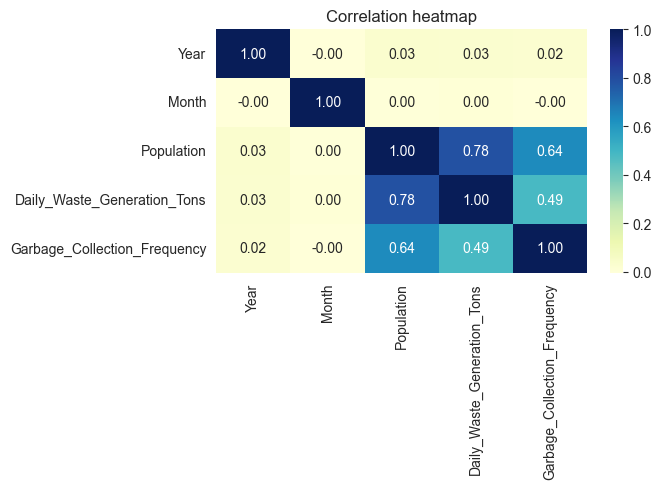

In [21]:
num = df.select_dtypes("number")
plt.figure(figsize=(7, 5)); sns.heatmap(num.corr(), annot=True, cmap="YlGnBu", fmt=".2f"); plt.title("Correlation heatmap")
save("eda_corr.png")

**EDA takeaways:** waste type and city size (Metro ≫ Tier-3) dominate; the target is strongly right-skewed, so we model `log1p(target)` and convert back to tons for scoring. Outliers are real (big metros) – kept, not removed.

## Step 4 – Encoding, split, scaling (manual)

In [22]:
X = pd.get_dummies(df.drop(columns=[target]), columns=["State", "City_Category", "Waste_Type"], drop_first=True, dtype=int)
Y = df[target]
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.20, random_state=42)
Ylog_train = np.log1p(Y_train)
scaler = StandardScaler().fit(X_train)            # used by LR & KNN only
Xs_train, Xs_test = scaler.transform(X_train), scaler.transform(X_test)
print(X_train.shape, X_test.shape)

# Low / Medium / High bins (for confusion matrix) – cut points from TRAIN tertiles
q = Y_train.quantile([1/3, 2/3]).values
bins = [-np.inf, q[0], q[1], np.inf]; labels = ["Low", "Medium", "High"]
to_cls = lambda y: pd.cut(y, bins=bins, labels=labels)
print("class cut-offs (tons):", q.round(2))

(20162, 50) (5041, 50)
class cut-offs (tons): [ 23.76 128.14]


## Step 5 – Model building

In [23]:
def mape(y, p): return np.mean(np.abs(y - p) / np.maximum(y, 1e-6)) * 100
def predict_tons(model, Xin): return np.clip(np.expm1(model.predict(Xin)), 0, None)

models = {
    "Linear Regression": (LinearRegression(), True),
    "Decision Tree": (DecisionTreeRegressor(random_state=42), False),
    "Random Forest": (RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1), False),
    "KNN": (KNeighborsRegressor(n_neighbors=5), True),
}
fitted = {}
for n, (m, scaled) in models.items():
    m.fit(Xs_train if scaled else X_train, Ylog_train); fitted[n] = (m, scaled)
print("trained:", list(fitted))

trained: ['Linear Regression', 'Decision Tree', 'Random Forest', 'KNN']


## Step 6 – Evaluation (before tuning)

                      R2  MAE (tons)  RMSE (tons)  R2 (log scale)  \
Linear Regression  0.831      51.666      227.740           0.970   
Decision Tree      0.983      22.603       72.086           0.994   
Random Forest      0.988      18.543       61.316           0.997   
KNN                0.980      28.855       77.947           0.961   

                   Class Accuracy  
Linear Regression           0.871  
Decision Tree               0.954  
Random Forest               0.963  
KNN                         0.889  


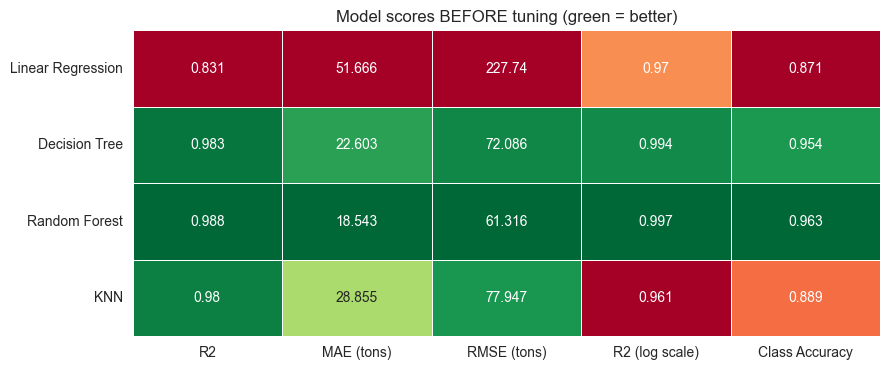

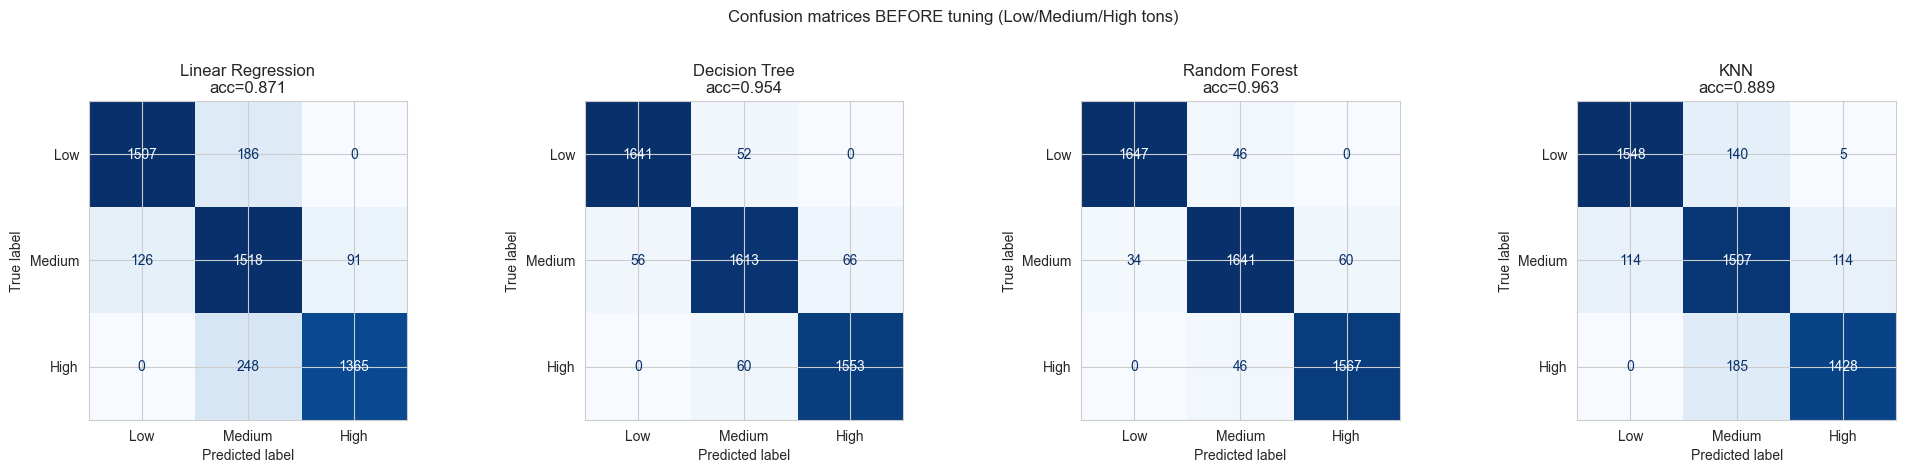

In [24]:
def evaluate(fitted):
    rows, preds = {}, {}
    for n, (m, scaled) in fitted.items():
        p = predict_tons(m, Xs_test if scaled else X_test); preds[n] = p
        rows[n] = {"R2": r2_score(Y_test, p), "MAE (tons)": mean_absolute_error(Y_test, p),
                   "RMSE (tons)": np.sqrt(mean_squared_error(Y_test, p)),
                   "R2 (log scale)": r2_score(np.log1p(Y_test), np.log1p(p)),
                   "Class Accuracy": accuracy_score(to_cls(Y_test), to_cls(pd.Series(p, index=Y_test.index)))}
    return pd.DataFrame(rows).T, preds

def score_heatmap(res, title, fname):
    z = (res - res.min()) / (res.max() - res.min())
    z["MAE (tons)"] = 1 - z["MAE (tons)"]; z["RMSE (tons)"] = 1 - z["RMSE (tons)"]   # colour: greener = better
    plt.figure(figsize=(9, 3.8)); sns.heatmap(z, annot=res.round(3), fmt="", cmap="RdYlGn", cbar=False, linewidths=.5)
    plt.title(title); save(fname)

def cm_grid(preds, title, fname):
    fig, ax = plt.subplots(1, 4, figsize=(20, 4.5))
    for a, (n, p) in zip(ax, preds.items()):
        cm = confusion_matrix(to_cls(Y_test), to_cls(pd.Series(p, index=Y_test.index)), labels=labels)
        ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=a, cmap="Blues", colorbar=False)
        a.set_title(f"{n}\nacc={np.trace(cm)/cm.sum():.3f}")
    fig.suptitle(title, y=1.03); save(fname)

res_before, preds_before = evaluate(fitted)
print(res_before.round(3))
score_heatmap(res_before, "Model scores BEFORE tuning (green = better)", "heatmap_before.png")
cm_grid(preds_before, "Confusion matrices BEFORE tuning (Low/Medium/High tons)", "cm_before.png")

## Step 7 – Hyper-parameter tuning

In [25]:
grids = {
    "Linear Regression": (LinearRegression(), {"fit_intercept": [True, False]}, True),
    "Decision Tree": (DecisionTreeRegressor(random_state=42),
                      {"max_depth": [6, 10, 14, 18, None], "min_samples_split": [2, 5, 10], "min_samples_leaf": [1, 3, 5]}, False),
    "Random Forest": (RandomForestRegressor(random_state=42, n_jobs=-1),
                      {"n_estimators": [100, 200, 300], "max_depth": [12, 18, None], "min_samples_leaf": [1, 2, 4],
                       "max_features": [0.5, 0.8, 1.0]}, False),
    "KNN": (KNeighborsRegressor(), {"n_neighbors": [3, 5, 7, 9, 12], "weights": ["uniform", "distance"], "p": [1, 2]}, True),
}
tuned, best_params = {}, {}
for n, (m, g, scaled) in grids.items():
    Xt = Xs_train if scaled else X_train
    if n == "Random Forest":
        s = RandomizedSearchCV(m, g, n_iter=8, cv=3, scoring="r2", random_state=42, n_jobs=1)
    else:
        s = GridSearchCV(m, g, cv=3, scoring="r2", n_jobs=-1)
    s.fit(Xt, Ylog_train); tuned[n] = (s.best_estimator_, scaled); best_params[n] = s.best_params_
    print(n, s.best_params_, round(s.best_score_, 4))

Linear Regression {'fit_intercept': True} 0.9693
Decision Tree {'max_depth': 14, 'min_samples_leaf': 5, 'min_samples_split': 2} 0.9959
Random Forest {'n_estimators': 200, 'min_samples_leaf': 4, 'max_features': 0.8, 'max_depth': None} 0.9968
KNN {'n_neighbors': 3, 'p': 2, 'weights': 'distance'} 0.958


                      R2  MAE (tons)  RMSE (tons)  R2 (log scale)  \
Linear Regression  0.831      51.666      227.740           0.970   
Decision Tree      0.986      19.832       66.622           0.996   
Random Forest      0.988      18.056       60.399           0.997   
KNN                0.981      28.208       75.778           0.968   

                   Class Accuracy  
Linear Regression           0.871  
Decision Tree               0.960  
Random Forest               0.963  
KNN                         0.889  


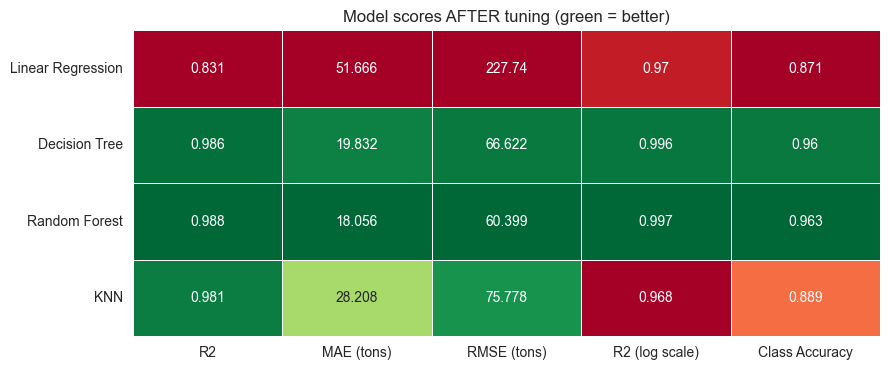

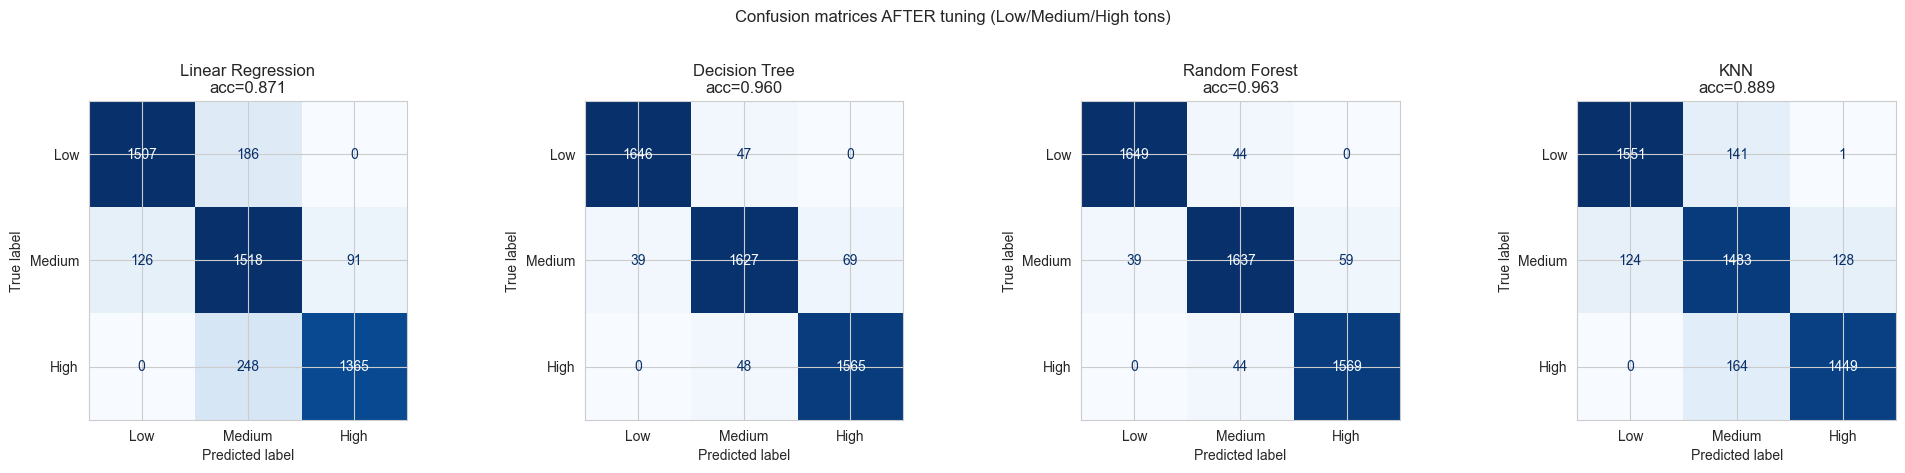

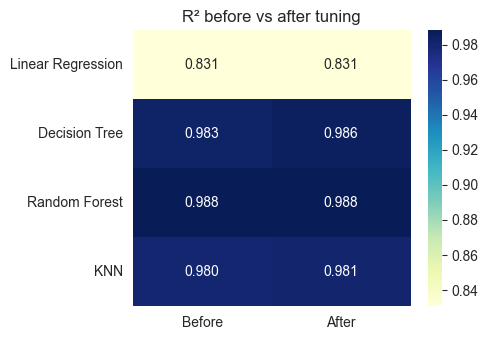

In [26]:
res_after, preds_after = evaluate(tuned)
print(res_after.round(3))
score_heatmap(res_after, "Model scores AFTER tuning (green = better)", "heatmap_after.png")
cm_grid(preds_after, "Confusion matrices AFTER tuning (Low/Medium/High tons)", "cm_after.png")
cmp = pd.concat({"Before": res_before["R2"], "After": res_after["R2"]}, axis=1)
plt.figure(figsize=(5, 3.5)); sns.heatmap(cmp, annot=True, fmt=".3f", cmap="YlGnBu"); plt.title("R² before vs after tuning")
save("heatmap_r2_compare.png")

## Best model & actual vs predicted

BEST MODEL: Random Forest {'n_estimators': 200, 'min_samples_leaf': 4, 'max_features': 0.8, 'max_depth': None}
       Actual  Predicted  Residuals
312      4.20       5.37      -1.17
23481   38.26      39.07      -0.81
21560   24.93      25.68      -0.75
11013   46.84      45.75       1.09
14112   77.09      69.57       7.52
19608   79.34      84.77      -5.43
10090   28.18      33.05      -4.87
10392  105.13     121.73     -16.60
13215  288.30     270.42      17.88
9861   107.55     118.51     -10.96


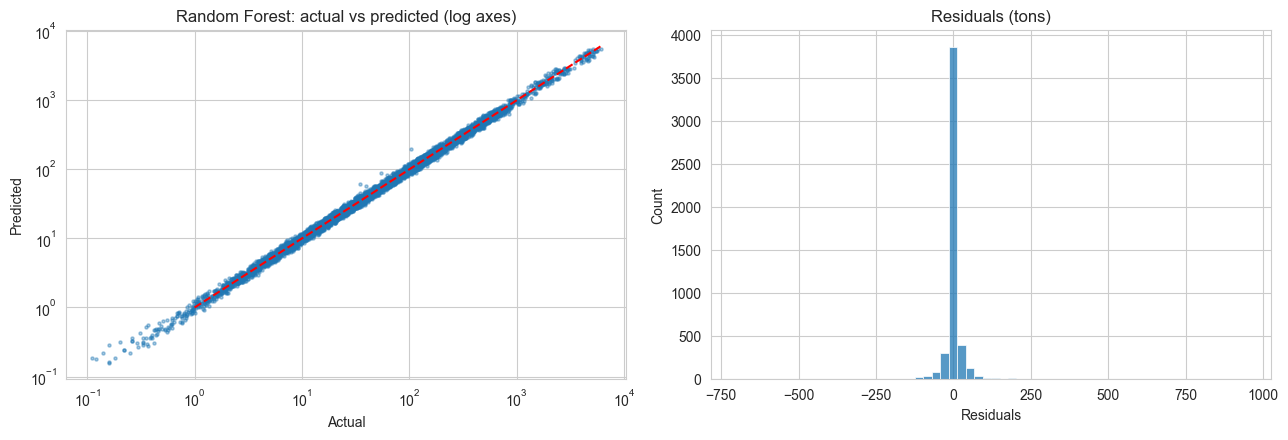

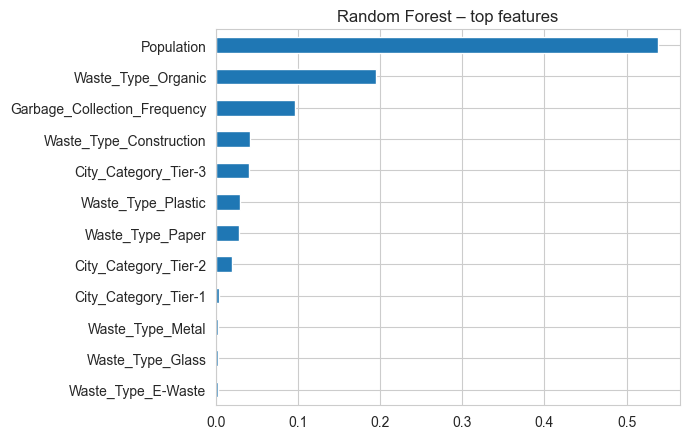

In [27]:
best = res_after["R2"].idxmax(); print("BEST MODEL:", best, best_params[best])
bm, bscaled = tuned[best]
bp = preds_after[best]
dt = pd.DataFrame({"Actual": Y_test, "Predicted": bp}); dt["Residuals"] = dt.Actual - dt.Predicted
print(dt.head(10).round(2))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(dt.Actual, dt.Predicted, s=5, alpha=.4); lim = [1, dt.Actual.max()]
ax[0].plot(lim, lim, "r--"); ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set(title=f"{best}: actual vs predicted (log axes)", xlabel="Actual", ylabel="Predicted")
sns.histplot(dt.Residuals, bins=60, ax=ax[1]); ax[1].set_title("Residuals (tons)")
save("best_model_fit.png")
if hasattr(bm, "feature_importances_"):
    imp = pd.Series(bm.feature_importances_, index=X.columns).sort_values().tail(12)
    plt.figure(figsize=(7, 4.5)); imp.plot.barh(title=f"{best} – top features"); save("feature_importance.png")

## Predict daily tons for a state / city
The dataset records only some waste types per city-month (~1.35 rows per city-month), so there is no "true total" in the data.
`predict_city` therefore returns the model's estimate of **all 9 waste types combined** (full city total tons/day);
pass `waste_types=[...]` to get a specific stream. A state total = sum over its cities.

In [28]:
full = data.copy()
ALL_TYPES = sorted(full.Waste_Type.unique())
def _row_features(frame):
    Z = pd.get_dummies(frame[["State", "City_Category", "Year", "Month", "Population", "Waste_Type", "Garbage_Collection_Frequency"]],
                       columns=["State", "City_Category", "Waste_Type"], dtype=int)
    return Z.reindex(columns=X.columns, fill_value=0)

def predict_city(city, year, month, waste_types=None):
    """Tons/day for a city in a given year & month (population taken from that month if known, else the latest record)."""
    c = full[full.City == city].sort_values(["Year", "Month"])
    exact = c[(c.Year == year) & (c.Month == month)]
    h = exact.iloc[0] if len(exact) else c.iloc[-1]
    rows = pd.DataFrame({"State": h.State, "City_Category": h.City_Category, "Year": year, "Month": month,
                         "Population": h.Population, "Waste_Type": waste_types or ALL_TYPES,
                         "Garbage_Collection_Frequency": h.Garbage_Collection_Frequency})
    Z = _row_features(rows); Z = scaler.transform(Z) if bscaled else Z
    return predict_tons(bm, Z).sum()

def predict_state(state, year, month, waste_types=None):
    return sum(predict_city(c, year, month, waste_types) for c in full[full.State == state].City.unique())

# sanity check against recorded rows (same waste types as recorded)
for c in ["Mumbai", "Agra", "Agartala"]:
    r = full[(full.City == c) & (full.Year == 2025) & (full.Month == 6)]
    print(f"{c:9s} Jun-2025 recorded {r.Daily_Waste_Generation_Tons.sum():8.1f} t | model on same types "
          f"{predict_city(c, 2025, 6, list(r.Waste_Type)):8.1f} t | model full total (all 9 types) {predict_city(c, 2025, 6):8.1f} t/day")
print("Uttar Pradesh Jun-2025 full-state estimate:", round(predict_state("Uttar Pradesh", 2025, 6), 1), "t/day")
res_after.to_csv(OUT + "results_after_tuning.csv"); res_before.to_csv(OUT + "results_before_tuning.csv")

Mumbai    Jun-2025 recorded    969.4 t | model on same types    969.2 t | model full total (all 9 types)  10962.0 t/day
Agra      Jun-2025 recorded     28.8 t | model on same types     29.7 t | model full total (all 9 types)    856.6 t/day
Agartala  Jun-2025 recorded     31.2 t | model on same types     28.3 t | model full total (all 9 types)     59.2 t/day
Uttar Pradesh Jun-2025 full-state estimate: 12733.3 t/day
